---
title: "Лабораторна робота 2. Дослідження нелінійної та стохастичної динаміки складної системи"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib

format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка

Лабораторна робота продовжує ЛР1 та спирається на Лекцію 2.

У ЛР1 було сформовано *версію 0.1* наскрізного модельного артефакту:

$$
RQ
\rightarrow
\text{Model Specification}
\rightarrow
\text{Mathematical Model}
\rightarrow
\text{Executable Model}.
$$

У ЛР2 додаємо наступний дослідницький шар:

$$
\text{Model}
\rightarrow
\text{Regimes}
\rightarrow
\text{Initial-condition sensitivity}
\rightarrow
\text{Stochastic perturbation}
\rightarrow
\text{Interpretation}.
$$

Стохастичний компонент тут вводиться практично як міст до Теми 4. Його систематичну теоретичну інтерпретацію буде розгорнуто в Лекції 3.
:::

# Мета роботи

Набути практичної здатності досліджувати режими нелінійної динамічної моделі, виявляти якісні зміни поведінки зі зміною параметрів, оцінювати чутливість до початкових умов, вводити контрольоване стохастичне збурення та розрізняти детерміновану складність і випадкову мінливість результатів.

# Завдання роботи

1. Реалізувати детерміновану нелінійну модель.
2. Дослідити її поведінку в різних параметричних режимах.
3. Побудувати карту режимів у формі біфуркаційної діаграми.
4. Дослідити чутливість до початкових умов.
5. Кількісно оцінити швидкість розходження близьких траєкторій.
6. Додати контрольоване стохастичне збурення.
7. Провести ансамбль стохастичних реалізацій.
8. Порівняти deterministic chaos і stochastic variability.
9. Виконати критичний аудит отриманих результатів.
10. Перенести процедуру на модель власного дисертаційного дослідження.

# Теоретичні відомості

Розглянемо дискретну динамічну систему

$$
X_{t+1}=F(X_t;\Theta).
$$

Навіть за фіксованого правила $F$ поведінка може якісно змінюватися зі зміною параметрів $\Theta$ або початкового стану $X_0$ [@strogatz2015; @sayama2015].

Для нелінійної моделі важливо досліджувати не одну траєкторію, а *простір режимів*:

$$
(\Theta,X_0)
\longrightarrow
\text{dynamic regime}.
$$

Якщо до моделі вводиться випадкова компонента,

$$
X_{t+1}=F(X_t;\Theta)+\varepsilon_t,
$$

то однакові $\Theta$ та $X_0$ вже можуть породжувати різні реалізації. Тому одиничний запуск стохастичної моделі не характеризує її поведінку -- потрібний *ансамбль реалізацій (ensemble)*.

## Логіка лабораторної роботи

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    M("Детермінована<br/>модель") --> R("Карта<br/>режимів")
    R --> I("Чутливість до<br/>початкових умов")
    I --> S("Стохастичне<br/>збурення")
    S --> E("Ансамбль<br/>реалізацій")
    E --> C("Порівняння:<br/>chaos vs noise")
    C --> A("Критичний<br/>аудит")
```

# Частина I. Навчальний кейс

Як контрольований навчальний полігон використаємо логістичне відображення

$$
x_{t+1}=r x_t(1-x_t),
\qquad
0\le x_t\le 1.
$$

Модель навмисно проста. Її цінність для цієї роботи полягає в тому, що зміна одного параметра $r$ породжує різні якісні режими -- від стійкого стану до періодичних коливань і детермінованого хаосу [@strogatz2015].

::: callout-important
## Методологічний принцип

Ми використовуємо логістичне відображення не як «модель усіх складних систем», а як *контрольований обчислювальний об'єкт*, на якому можна розділити механізми:

$$
\text{nonlinearity}
\neq
\text{chaos}
\neq
\text{randomness}.
$$
:::

# 1. Реалізація детермінованої моделі

Створимо функцію, яка повертає повну траєкторію.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def logistic_map(r, x0=0.2, n=300):
    """Детерміноване логістичне відображення."""
    x = np.empty(n, dtype=float)
    x[0] = x0

    for t in range(n - 1):
        x[t + 1] = r * x[t] * (1 - x[t])

    return x

# 2. Базові перевірки

До інтерпретації результату виконаємо мінімальні *sanity checks*.

Для стандартного логістичного відображення при $0\le r\le4$ і $0\le x_0\le1$ траєкторія має залишатися в $[0,1]$.

In [2]:
trajectory = logistic_map(r=3.2, x0=0.2, n=300)

assert np.isfinite(trajectory).all()
assert ((trajectory >= 0) & (trajectory <= 1)).all()

print("min =", trajectory.min())
print("max =", trajectory.max())
print("Останні 10 значень:")
print(np.round(trajectory[-10:], 6))

min = 0.2
max = 0.7995392
Останні 10 значень:
[0.799455 0.513045 0.799455 0.513045 0.799455 0.513045 0.799455 0.513045
 0.799455 0.513045]


# 3. Порівняння кількох режимів

Дослідимо ту саму модель за чотирьох значень $r$:

- $r=2.8$;
- $r=3.2$;
- $r=3.5$;
- $r=3.9$.

Важливо: ми змінюємо **один параметр**, а не клас моделі.

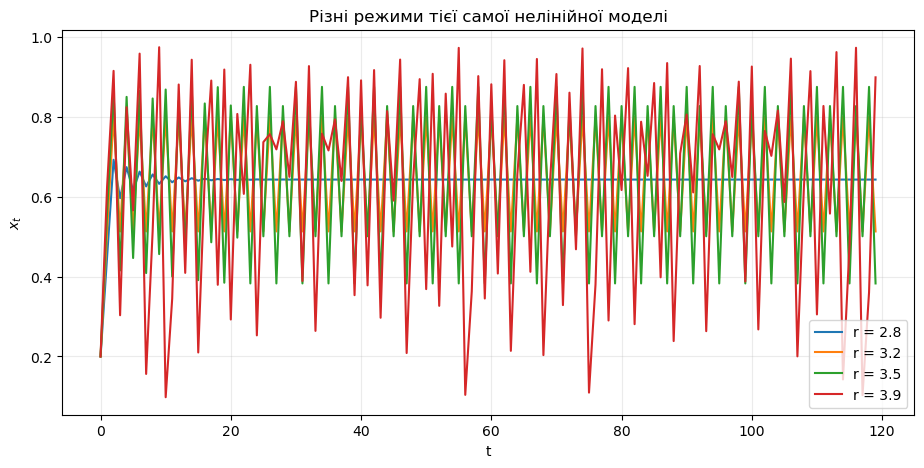

In [3]:
r_values = [2.8, 3.2, 3.5, 3.9]
x0 = 0.2
n = 120

plt.figure(figsize=(11, 5))

for r in r_values:
    x = logistic_map(r=r, x0=x0, n=n)
    plt.plot(range(n), x, label=f"r = {r}")

plt.xlabel("t")
plt.ylabel("$x_t$")
plt.title("Різні режими тієї самої нелінійної моделі")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Завдання 3.1

Для кожного значення $r$ визначте спостережуваний режим після завершення перехідного процесу.

| $r$ | Спостережуваний режим | Обґрунтування |
|---:|---|---|
| 2.8 | | |
| 3.2 | | |
| 3.5 | | |
| 3.9 | | |

Не використовуйте слово «хаос» лише тому, що графік виглядає нерегулярним. Потрібні додаткові ознаки.

# 4. Від траєкторії до карти режимів

Один графік $x_t$ відповідає лише одній точці параметричного простору.

Для дослідження структури режимів побудуємо біфуркаційну діаграму:

$$
r
\longrightarrow
\{x_t\}_{t\gg1}.
$$

Перехідні значення відкидаємо, оскільки нас цікавить асимптотична поведінка.

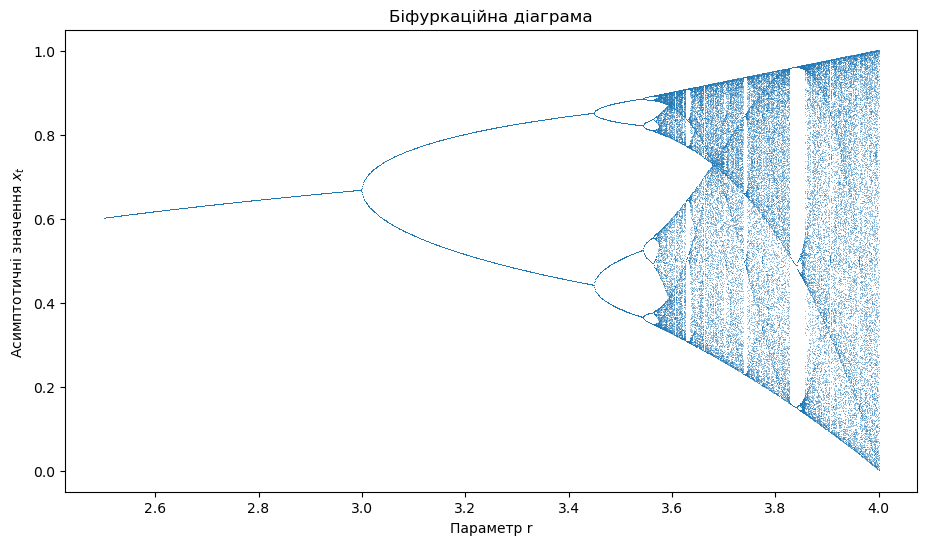

In [4]:
r_grid = np.linspace(2.5, 4.0, 1400)

r_plot = []
x_plot = []

for r in r_grid:
    x = logistic_map(r=r, x0=0.2, n=1400)

    # Відкидаємо перехідний процес.
    asymptotic = x[-150:]

    r_plot.extend([r] * len(asymptotic))
    x_plot.extend(asymptotic)

plt.figure(figsize=(11, 6))
plt.plot(r_plot, x_plot, ",", alpha=0.45)
plt.xlabel("Параметр r")
plt.ylabel("Асимптотичні значення $x_t$")
plt.title("Біфуркаційна діаграма")
plt.show()

## Завдання 4.1

За біфуркаційною діаграмою знайдіть приблизні області:

1. стійкого стаціонарного режиму;
2. періоду 2;
3. подальшого подвоєння періоду;
4. хаотичної поведінки;
5. періодичних «вікон» усередині хаотичної області.

Сформулюйте, чому біфуркаційна діаграма дає більше інформації про модель, ніж один часовий ряд.

# 5. Чутливість до початкових умов

Візьмемо хаотичний режим $r=3.9$ та два дуже близькі початкові стани:

$$
x_0^{(A)}=0.200000,
$$

$$
x_0^{(B)}=0.200001.
$$

Початкова різниця:

$$
\delta_0=
\left|
x_0^{(A)}-x_0^{(B)}
\right|
=10^{-6}.
$$

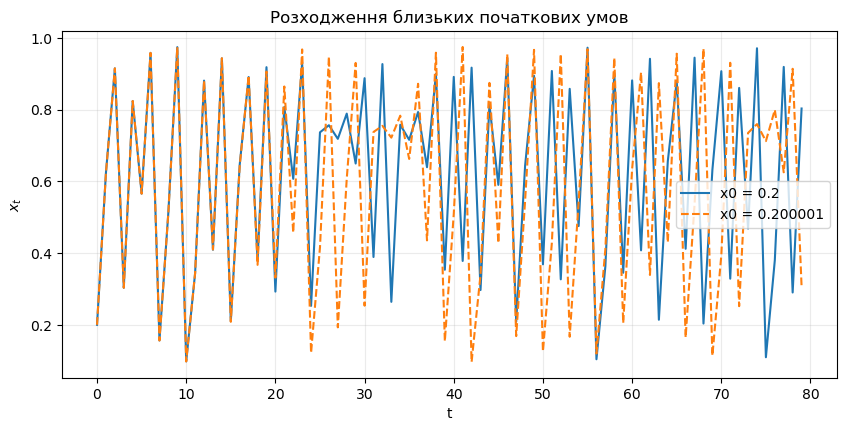

In [5]:
r = 3.9
x0_a = 0.200000
x0_b = 0.200001
n = 80

xa = logistic_map(r, x0_a, n)
xb = logistic_map(r, x0_b, n)

plt.figure(figsize=(10, 4.5))
plt.plot(xa, label=f"x0 = {x0_a}")
plt.plot(xb, "--", label=f"x0 = {x0_b}")
plt.xlabel("t")
plt.ylabel("$x_t$")
plt.title("Розходження близьких початкових умов")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

# 6. Кількісне вимірювання розходження

Обчислимо

$$
\delta_t=
\left|
x_t^{(A)}-x_t^{(B)}
\right|.
$$

Якщо на певному інтервалі

$$
\delta_t
\approx
\delta_0 e^{\lambda t},
$$

то

$$
\ln\delta_t
\approx
\ln\delta_0+\lambda t.
$$

Тому початковий майже лінійний ріст $\ln\delta_t$ є практичною ознакою експоненційного розходження.

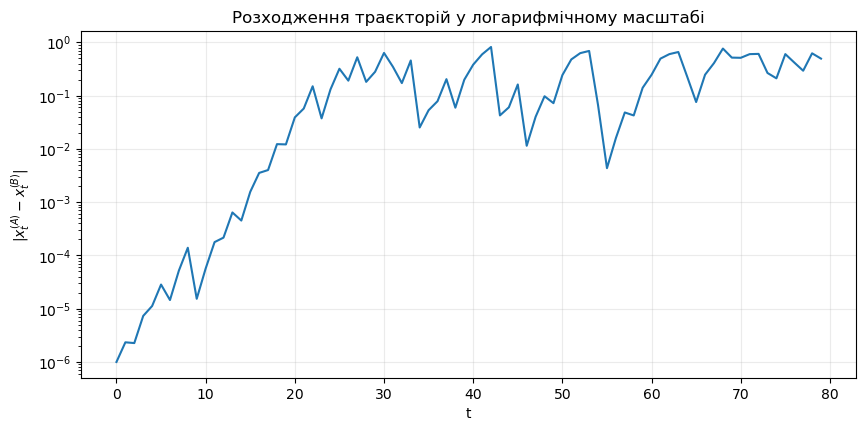

In [6]:
delta = np.abs(xa - xb)

# Захищаємо логарифм від log(0).
delta_safe = np.maximum(delta, 1e-16)

plt.figure(figsize=(10, 4.5))
plt.semilogy(range(n), delta_safe)
plt.xlabel("t")
plt.ylabel("$|x_t^{(A)} - x_t^{(B)}|$")
plt.title("Розходження траєкторій у логарифмічному масштабі")
plt.grid(alpha=0.25)
plt.show()

## Завдання 6.1

Поясніть:

1. чому траєкторії спочатку майже збігаються;
2. чому згодом прогноз конкретного стану втрачає надійність;
3. чому це **не означає**, що модель стала стохастичною;
4. чому після насичення різниці просте експоненційне наближення вже не працює.

# 7. Оцінка показника Ляпунова

Для логістичного відображення

$$
f(x)=rx(1-x)
$$

маємо

$$
f'(x)=r(1-2x).
$$

Найбільший показник Ляпунова для довгої траєкторії можна оцінити як

$$
\lambda
\approx
\frac{1}{N}
\sum_{t=1}^{N}
\ln
\left|
r(1-2x_t)
\right|.
$$

Якщо $\lambda>0$, близькі траєкторії в середньому експоненційно розходяться [@strogatz2015].

In [7]:
def lyapunov_logistic(r, x0=0.2, n=6000, burn_in=1000):
    x = logistic_map(r=r, x0=x0, n=n)

    x_use = x[burn_in:]
    derivatives = np.abs(r * (1 - 2 * x_use))

    # Уникаємо log(0).
    derivatives = np.maximum(derivatives, 1e-16)

    return np.mean(np.log(derivatives))

for r in [2.8, 3.2, 3.5, 3.9]:
    lam = lyapunov_logistic(r)
    print(f"r = {r:.1f}: lambda ≈ {lam:.4f}")

r = 2.8: lambda ≈ -0.2231
r = 3.2: lambda ≈ -0.9163
r = 3.5: lambda ≈ -0.8725
r = 3.9: lambda ≈ 0.4978


## Завдання 7.1

Порівняйте знак $\lambda$ з режимами, які Ви визначили раніше.

Зробіть висновок:

> Чим твердження «графік виглядає хаотично» відрізняється від кількісного аргументу на основі $\lambda$?

# 8. Перехід до стохастичної моделі

Тепер **змінимо саму модель**.

Додамо випадкове збурення:

$$
x_{t+1}
=
r x_t(1-x_t)
+
\sigma \xi_t,
$$

де

$$
\xi_t\sim\mathcal{N}(0,1),
$$

а $\sigma$ визначає інтенсивність шуму.

Це вже стохастична модель: за однакових $r$, $x_0$ та $\sigma$ різні послідовності $\xi_t$ породжують різні траєкторії.

::: callout-warning
## Важливо

У навчальному прикладі шум вводиться як контрольоване математичне збурення. Не слід автоматично інтерпретувати $\xi_t$ як конкретний фізичний або соціальний механізм. Для реальної моделі джерело стохастичності має бути обґрунтоване.
:::

# 9. Відтворюваний генератор випадковості

Використовуємо `numpy.random.default_rng`.

Документація: [NumPy random sampling](https://numpy.org/doc/stable/reference/random/index.html).

Фіксація `seed` не робить процес детермінованим у модельному сенсі. Вона робить **конкретний обчислювальний експеримент відтворюваним**.

In [8]:
def stochastic_logistic_map(r, sigma, x0=0.2, n=300, seed=None):
    """
    Стохастичне логістичне відображення
    з адитивним Gaussian noise.
    """
    rng = np.random.default_rng(seed)

    x = np.empty(n, dtype=float)
    x[0] = x0

    for t in range(n - 1):
        noise = sigma * rng.normal()
        x[t + 1] = r * x[t] * (1 - x[t]) + noise

        # Для навчального кейсу обмежуємо стан інтервалом [0, 1].
        x[t + 1] = np.clip(x[t + 1], 0.0, 1.0)

    return x

::: callout-important
## Що означає `clip`?

Операція

```python
np.clip(x, 0.0, 1.0)
```

є **додатковим модельним рішенням**, а не нейтральною технічною деталлю.

Ми припускаємо, що стан не може залишити $[0,1]$. В іншій предметній задачі правильним рішенням може бути інша гранична умова або інша форма стохастичного члена.

Цей приклад демонструє загальний принцип: навіть невелика програмна операція може містити модельне припущення.
:::

# 10. Одна стохастична реалізація -- ще не поведінка моделі

Порівняємо детерміновану траєкторію з однією стохастичною реалізацією.

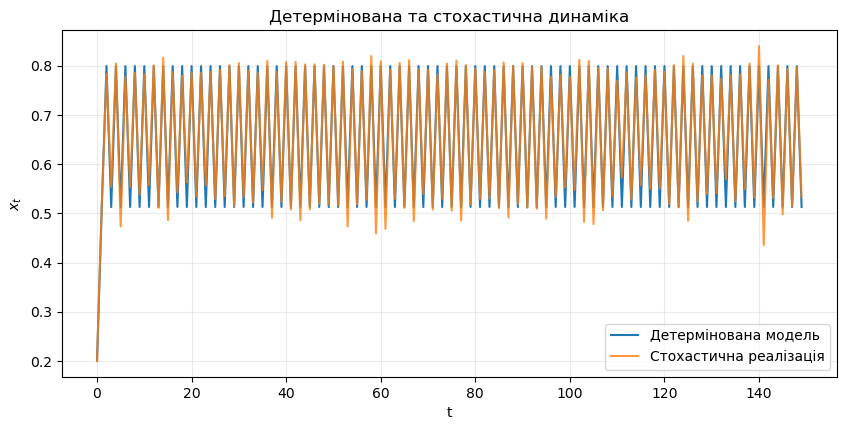

In [9]:
r = 3.2
sigma = 0.015
n = 150

x_det = logistic_map(r=r, x0=0.2, n=n)
x_stoch = stochastic_logistic_map(
    r=r,
    sigma=sigma,
    x0=0.2,
    n=n,
    seed=42
)

plt.figure(figsize=(10, 4.5))
plt.plot(x_det, label="Детермінована модель")
plt.plot(x_stoch, alpha=0.8, label="Стохастична реалізація")
plt.xlabel("t")
plt.ylabel("$x_t$")
plt.title("Детермінована та стохастична динаміка")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Завдання 10.1

Повторіть стохастичний запуск із `seed=1`, `seed=2`, `seed=3`.

Поясніть:

- що залишається незмінним;
- що змінюється;
- чому вибір «найкрасивішої» реалізації для звіту є методологічно некоректним.

# 11. Ансамбль реалізацій (ensemble)

Для стохастичної моделі досліджуємо не одну траєкторію, а множину

$$
\left\{
X_t^{(1)},X_t^{(2)},\ldots,X_t^{(M)}
\right\}.
$$

Для кожного $t$ можна оцінити, наприклад,

$$
\bar{x}_t=
\frac{1}{M}
\sum_{m=1}^{M}x_t^{(m)}
$$

та емпіричні квантілі.

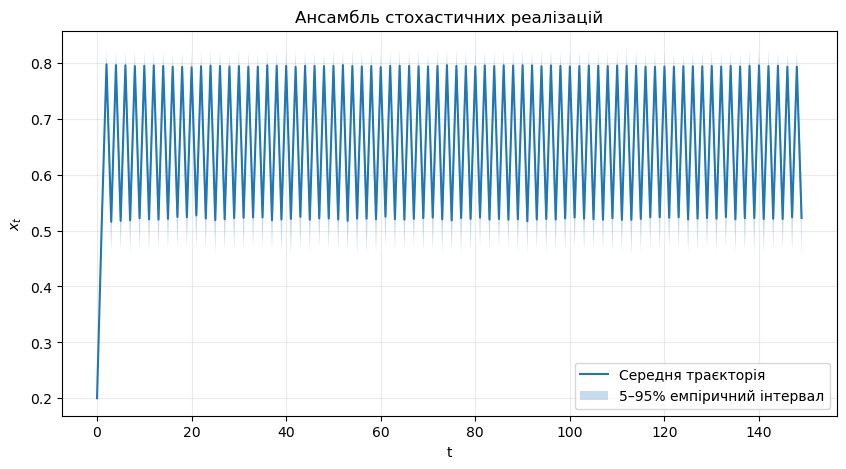

In [10]:
M = 300
n = 150
r = 3.2
sigma = 0.015

ensemble = np.empty((M, n))

for m in range(M):
    ensemble[m] = stochastic_logistic_map(
        r=r,
        sigma=sigma,
        x0=0.2,
        n=n,
        seed=1000 + m
    )

mean_path = ensemble.mean(axis=0)
q05 = np.quantile(ensemble, 0.05, axis=0)
q95 = np.quantile(ensemble, 0.95, axis=0)

plt.figure(figsize=(10, 5))
plt.plot(mean_path, label="Середня траєкторія")
plt.fill_between(
    np.arange(n),
    q05,
    q95,
    alpha=0.25,
    label="5–95% емпіричний інтервал"
)
plt.xlabel("t")
plt.ylabel("$x_t$")
plt.title("Ансамбль стохастичних реалізацій")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Інтерпретація ансамблю

Смуга між 5-м і 95-м емпіричними квантилями характеризує *розкид реалізацій моделі* за заданої стохастичної постановки.

На цьому етапі її не слід називати:

- довірчим інтервалом параметра;
- похибкою реального вимірювання;
- повною невизначеністю прогнозу.

Ці поняття мають різний зміст. Формальну типологію невизначеностей розглянемо в Темі 4, а UQ -- у Темі 10 [@smith2024].

# 12. Ефект інтенсивності шуму

Тепер змінюємо $\sigma$, залишаючи інші умови фіксованими.

Це контрольований експеримент:

$$
\sigma
\longrightarrow
\text{розподіл модельних траєкторій}.
$$

In [11]:
sigma_values = [0.0, 0.005, 0.015, 0.04]
M = 200
n = 150
r = 3.2

summary = []

for sigma in sigma_values:
    final_values = []

    for m in range(M):
        x = stochastic_logistic_map(
            r=r,
            sigma=sigma,
            x0=0.2,
            n=n,
            seed=5000 + m
        )
        final_values.append(x[-1])

    final_values = np.asarray(final_values)

    summary.append({
        "sigma": sigma,
        "mean_final": final_values.mean(),
        "std_final": final_values.std(ddof=1),
        "q05_final": np.quantile(final_values, 0.05),
        "q95_final": np.quantile(final_values, 0.95),
    })

pd.DataFrame(summary)

,sigma,mean_final,std_final,q05_final,q95_final
0,0.000,0.513045,1.113009e-16,0.513045,0.513045
1,0.005,0.513702,1.061251e-02,0.497890,0.530371
2,0.015,0.520584,3.384408e-02,0.469190,0.573571
3,0.040,0.659552,1.271827e-01,0.448244,0.831101


## Завдання 12.1

Поясніть, як зі збільшенням $\sigma$ змінюються:

- середнє кінцеве значення;
- стандартне відхилення;
- емпіричний інтервал 5--95%.

Чи обов'язково більший шум має змінювати лише дисперсію, залишаючи середнє незмінним?

Зверніть увагу на нелінійність та на використану нами операцію `clip`.

# 13. Chaos і noise -- два різні джерела нерегулярності

Порівняємо дві постановки.

### A. Детермінований хаос

$$
x_{t+1}=3.9x_t(1-x_t),
\qquad \sigma=0.
$$

### B. Стохастична мінливість у нехаотичному режимі

$$
x_{t+1}=3.2x_t(1-x_t)+\sigma\xi_t.
$$

В обох випадках часовий ряд може виглядати нерегулярним. Але механізм нерегулярності різний.

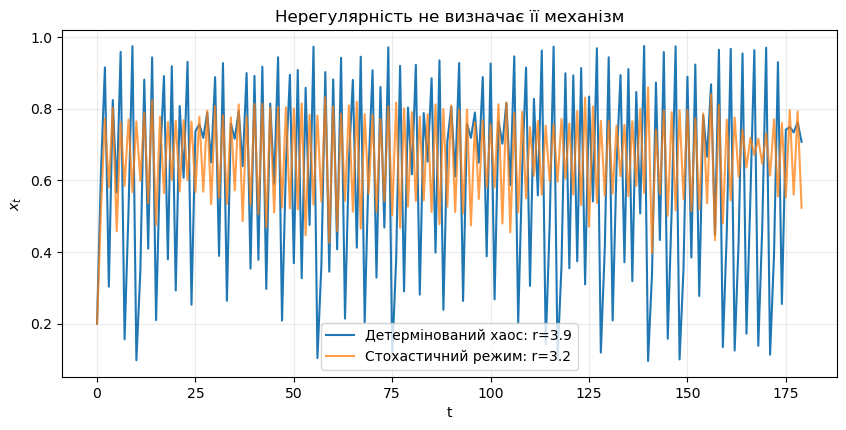

In [12]:
n = 180

chaotic = logistic_map(
    r=3.9,
    x0=0.2,
    n=n
)

noisy = stochastic_logistic_map(
    r=3.2,
    sigma=0.025,
    x0=0.2,
    n=n,
    seed=42
)

plt.figure(figsize=(10, 4.5))
plt.plot(chaotic, label="Детермінований хаос: r=3.9")
plt.plot(noisy, alpha=0.75, label="Стохастичний режим: r=3.2")
plt.xlabel("t")
plt.ylabel("$x_t$")
plt.title("Нерегулярність не визначає її механізм")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Завдання 13.1

Заповніть таблицю.

| Ознака | Детермінований хаос | Стохастична мінливість |
|---|---|---|
| Правило еволюції | | |
| Випадкова компонента | | |
| Повторний запуск за тих самих умов | | |
| Чутливість до $x_0$ | | |
| Роль `seed` | | |
| Що означає ансамбль | | |

Сформулюйте головний висновок:

> Чому нерегулярний часовий ряд сам по собі не дозволяє визначити механізм, який його породив?

# 14. Критичний аудит навчального експерименту

| Питання аудиту | Відповідь здобувача |
|---|---|
| Які режими детермінованої моделі виявлено? | |
| Які ознаки використано для твердження про хаос? | |
| Яку роль відіграє початкова умова? | |
| Яке саме джерело випадковості введено? | |
| Чи має Gaussian noise предметну інтерпретацію? | |
| Яке модельне припущення містить `clip`? | |
| Чому одна stochastic realization недостатня? | |
| Що показує ensemble? | |
| Які висновки стосуються лише математичної моделі? | |
| Яких даних бракує для твердження про реальну систему? | |

::: callout-tip
## Критерій якості

Результатом ЛР2 є не твердження «модель хаотична/стохастична», а *аргументована карта режимів і пояснення джерел мінливості*.
:::

# Частина II. Перенесення на дисертаційне дослідження

Поверніться до *паспорта моделі* з ЛР1.

Мета цієї частини -- не обов'язково зробити Вашу дисертаційну модель хаотичною або стохастичною. Потрібно встановити, **які види динамічної мінливості взагалі релевантні Вашому RQ**.

# 15. Аудит динамічної постановки

Заповніть таблицю.

| Питання | Відповідь |
|---|---|
| Яка змінна/вектор описує стан? | |
| Які параметри керують динамікою? | |
| Які початкові умови потрібні? | |
| Який часовий масштаб? | |
| Чи очікуються різні режими? | |
| Чи можливі порогові переходи? | |
| Чи релевантна чутливість до $X_0$? | |
| Які джерела випадковості існують у предметній системі? | |
| Які з них варто включити до моделі? | |
| Що є невизначеним, але не випадковим? | |

# 16. Мінімальний детермінований експеримент

Для моделі з ЛР1 оберіть:

- один параметр $\theta$ або структурне припущення;
- один вихід $Y$;
- один діапазон зміни $\theta$.

Побудуйте експеримент

$$
\theta
\longrightarrow
Y(\theta).
$$

Перевірте, чи зміна є:

- монотонною;
- немонотонною;
- пороговою;
- режимною;
- практично відсутньою.

Не називайте це повним *Sensitivity Analysis* -- систематичний локальний і глобальний аналіз чутливості буде в Темі 10.

# 17. Експеримент із початковими умовами

Якщо це змістовно для Вашої моделі, порівняйте

$$
X_0
\quad\text{та}\quad
X_0+\delta.
$$

Дослідіть

$$
d(t)=
\left\|
X^{(1)}(t)-X^{(2)}(t)
\right\|.
$$

Якщо чутливість до початкових умов не є релевантною для Вашого класу моделі, обґрунтуйте це замість штучного виконання процедури.

# 18. Стохастичне розширення -- лише за наявності механізму

Якщо у предметній системі є обґрунтоване джерело випадковості, сформулюйте:

$$
X_{t+1}
=
F(X_t,U_t,\Theta,\varepsilon_t)
$$

або іншу відповідну стохастичну постановку.

Опишіть:

1. що означає $\varepsilon_t$ у предметній області;
2. чому обрано саме такий розподіл;
3. чи є шум адитивним, мультиплікативним або структурним;
4. чи залежить він від стану;
5. які параметри його розподілу відомі, а які потребують оцінювання.

::: callout-warning
## Не додавайте noise «для реалістичності»

Стохастичність повинна відповідати модельованому механізму. Якщо для Вашого RQ випадковий компонент не потрібний, аргументоване рішення *не вводити його* є коректним результатом.
:::

# 19. Ансамблевий експеримент власної моделі

Якщо стохастичне розширення обґрунтоване:

1. виконайте не менше $M=100$ реалізацій;
2. збережіть `seed` або правило його формування;
3. оберіть один змістовний observable $Y$;
4. оцініть середнє, стандартне відхилення та квантілі;
5. побудуйте візуалізацію ансамблю;
6. поясніть, *який саме тип мінливості* відображає отриманий розкид.

Якщо стохастичність не потрібна, запропонуйте дизайн ансамблю за іншою невизначеною величиною, але чітко поясніть, чому це вже не те саме, що stochastic process.

# 20. Оновлення паспорта моделі

Доповніть паспорт ЛР1 новим блоком.

| Динамічний аспект | Версія 0.2 |
|---|---|
| Основний режим / режими | |
| Керуючі параметри | |
| Початкові умови | |
| Ознаки нелінійності | |
| Можливі порогові переходи | |
| Чутливість до $X_0$ | |
| Джерела стохастичності | |
| Тип стохастичного механізму | |
| Observable для аналізу | |
| Потрібний ансамбль | |
| Невирішені питання | |

Таким чином:

$$
\text{Model Specification v0.1}
\longrightarrow
\text{Dynamic Model Specification v0.2}.
$$

# 21. Підсумковий артефакт ЛР2

Після виконання роботи має бути сформовано:

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {
  'fontSize': '18px',
  'fontFamily': 'Trebuchet MS, Verdana, Arial, sans-serif',
  'primaryColor': '#E8F3FF',
  'primaryBorderColor': '#3478A8',
  'secondaryColor': '#FFF0C9',
  'tertiaryColor': '#E7F6EC',
  'lineColor': '#536878'
}}}%%
flowchart LR
    A("Model Specification<br/>v0.1") --> B("Карта<br/>режимів")
    B --> C("Initial-condition<br/>experiment")
    C --> D("Stochastic<br/>mechanism")
    D --> E("Ensemble<br/>experiment")
    E --> F("Critical<br/>audit")
    F --> G("Dynamic Model<br/>Specification v0.2")
```

Цей артефакт стане основою для подальшого переходу від *динаміки окремої системи* до *структури та динаміки складних мереж*.

# Контрольні питання

1. Чому для нелінійної моделі однієї траєкторії недостатньо?
2. Що показує біфуркаційна діаграма?
3. Чим параметричний режим відрізняється від випадкової реалізації?
4. Що означає чутливість до початкових умов?
5. Чому детермінований хаос не є стохастичністю?
6. Який зміст має додатний показник Ляпунова?
7. Чому в хаотичному режимі детермінована модель може мати обмежений горизонт прогнозування?
8. Що змінюється після введення випадкової величини $\varepsilon_t$?
9. Навіщо фіксувати `seed`?
10. Чому одна стохастична реалізація недостатня для характеристики моделі?
11. Що таке ансамбль реалізацій?
12. Чим емпіричний квантильний інтервал ансамблю відрізняється від довірчого інтервалу?
13. Чому `clip` у навчальному прикладі є модельним припущенням?
14. Чому шум не слід додавати лише «для реалістичності»?
15. Як відрізнити stochastic variability від uncertainty у параметрах?
16. Які твердження після цієї лабораторної стосуються математичної моделі, а не реальної системи?

# Вимоги до звіту

Звіт виконується безпосередньо в `.ipynb`-зошиті.

Мають бути представлені:

1. результати дослідження режимів навчальної моделі;
2. біфуркаційна діаграма та її інтерпретація;
3. експеримент із близькими початковими умовами;
4. оцінка показника Ляпунова;
5. стохастичне розширення;
6. ансамбль реалізацій та його статистичний опис;
7. порівняння deterministic chaos і stochastic variability;
8. критичний аудит навчального кейсу;
9. перенесення процедури на дисертаційний об'єкт;
10. оновлений *Dynamic Model Specification v0.2*;
11. висновки з чітким розмежуванням тверджень про код, математичну модель та реальну систему.

::: callout-important
## Оцінюється

Не кількість графіків, а аргументованість ланцюга

$$
\text{parameter / initial condition / randomness}
\rightarrow
\text{dynamic regime}
\rightarrow
\text{observable evidence}
\rightarrow
\text{bounded interpretation}.
$$
:::

# Висновки

У висновках дайте відповіді на п'ять питань:

1. Які режими виявлено в досліджуваній моделі?
2. Які параметри та початкові умови визначають або змінюють ці режими?
3. Чи є нерегулярність детермінованою, стохастичною або змішаною?
4. Який результат стійкий на рівні ансамблю, а який залежить від окремої реалізації?
5. Що з отриманого можна стверджувати про математичну модель і чого ще не можна переносити на реальну систему?

# Джерела та корисні ресурси

Лабораторна робота використовує спільну накопичувальну бібліографічну базу курсу `mmss-references.bib`.

Корисні ресурси:

- [NumPy -- Random sampling](https://numpy.org/doc/stable/reference/random/index.html)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)
- [Introduction to the Modeling and Analysis of Complex Systems -- Hiroki Sayama](https://milneopentextbooks.org/introduction-to-the-modeling-and-analysis-of-complex-systems/)

# References